In [1]:
from IPython.display import clear_output

#clear_output()

In [6]:
!pip install pyyaml

In [9]:
!conda install conda-forge::kaggle --yes

Channels:
 - rapidsai
 - nvidia
 - nodefaults
 - conda-forge
 - defaults
 - pytorch
Platform: linux-64
Solving environment: done

# All requested packages already installed.



In [12]:
import yaml

def DCENetInstall():
    !cd /kaggle/working/ && mkdir DCENet
    !cd /kaggle/working/DCENet/

    env_data = {
        "name": "myenv",
        "channels": ["defaults"],
        "dependencies": ["numpy", "pandas"]
    }

    yaml_file_path = "/kaggle/working/DCENet/conda.yml"

    with open(yaml_file_path, 'w') as file:
        yaml.dump(env_data, file, default_flow_style=False)

    print(f"YAML file created: {yaml_file_path}")

    !cd /kaggle/working/DCENet/ &&conda env create -f conda.yml
    !source /opt/conda/bin/activate DCENet
    !/opt/conda/envs/DCENet/bin/python3 -m pip install -q tensorflow==2.4.1


In [13]:
DCENetInstall()

YAML file created: /kaggle/working/DCENet/conda.yml
/opt/conda/lib/python3.10/argparse.py:1943: FutureWarning: `remote_definition` is deprecated and will be removed in 25.9. Use `conda env create --file=URL` instead.
  action(self, namespace, argument_values, option_string)
Channels:
 - defaults
 - rapidsai
 - nvidia
 - nodefaults
 - conda-forge
Platform: linux-64
Solving environment: done

python-3.12.7        | 34.6 MB   |                                       |   0% 
pandas-2.2.2         | 15.4 MB   |                                       |   0% 

numpy-base-1.26.4    | 7.7 MB    |                                       |   0% 


libopenblas-0.3.21   | 5.4 MB    |                                       |   0% 



libgcc-ng-11.2.0     | 5.3 MB    |                                       |   0% 




openssl-3.0.15       | 5.2 MB    |                                       |   0% 





libstdcxx-ng-11.2.0  | 4.7 MB    |                                       |   0% 






tk-8.6.14         

# Image Enhahcement

In [14]:
import os
import random
import numpy as np
from glob import glob
from PIL import Image, ImageOps
from kaggle_secrets import UserSecretsClient

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid

import wandb

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, losses, optimizers, callbacks


AUTOTUNE = tf.data.AUTOTUNE


In [15]:
import cv2
import os
from PIL import Image, ImageEnhance
import numpy as np
from sklearn.model_selection import train_test_split

# Function to darken the image and simulate nighttime
def darken_image(image, factor=0.2):
    """
    Darken the image to simulate night-time by reducing the brightness.
    Args:
    image: PIL Image to be darkened.
    factor: Brightness reduction factor (0 means fully dark, 1 means no change).

    Returns:
    PIL Image: Darkened image.
    """
    enhancer = ImageEnhance.Brightness(image)
    darkened_image = enhancer.enhance(factor)  # Reduce brightness by factor
    return darkened_image

# Function to extract up to 10 frames at equal intervals from a video
def extract_frames(video_path, num_frames=10):
    """
    Extracts num_frames frames from a video at equal intervals.
    Args:
    video_path: Path to the video file.
    num_frames: Number of frames to extract.

    Returns:
    List of PIL Images (frames).
    """
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_interval = total_frames // num_frames
    frames = []

    for i in range(num_frames):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i * frame_interval)
        ret, frame = cap.read()
        if ret:
            # Convert OpenCV BGR format to RGB format and to PIL Image
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            pil_image = Image.fromarray(frame_rgb)
            frames.append(pil_image)
        else:
            print(f"Could not read frame {i * frame_interval} from video {video_path}")
    
    cap.release()
    return frames

# Main function to process all videos in subfolders (with a limit of 20 frames per subfolder)
def process_videos(root_folder):
    """
    Processes all videos in subfolders, extracts up to 20 frames per subfolder, 
    darkens them, and prepares X and y_true.
    Args:
    root_folder: The root directory containing subfolders with videos.

    Returns:
    X and y_true datasets (both as lists of PIL Images).
    """
    X_all = []       # Darkened images (input values)
    y_true_all = []  # Original images (true labels)

    # Iterate through each subfolder
    for subdir, dirs, files in os.walk(root_folder):
        X_subdir = []       # Darkened images for the current subfolder
        y_true_subdir = []  # Original images for the current subfolder

        for file in files:
            if file.endswith(('.mp4', '.avi', '.mkv')):  # Modify the file extensions if needed
                video_path = os.path.join(subdir, file)
                print(f"Processing video: {video_path}")
                
                # Extract 10 frames from the video
                frames = extract_frames(video_path, num_frames=10)
                
                # Process each frame: darken it and store both original and darkened frames
                for frame in frames:
                    if len(X_subdir) >= 100:  # Stop once 20 images are collected from the subfolder
                        break
                    
                    darkened_frame = darken_image(frame)
                    X_subdir.append(darkened_frame)      # Darkened frame (input)
                    y_true_subdir.append(frame)          # Original frame (target)

            if len(X_subdir) >= 100:  # Stop after processing enough frames from videos in the subfolder
                break

        # Add the subfolder's data to the global dataset
        X_all.extend(X_subdir)
        y_true_all.extend(y_true_subdir)

    return X_all, y_true_all

# Set the root folder where videos are stored
root_video_folder = '/kaggle/input/cctv-action-recognition-dataset/Videos/Videos/'

# Process the videos and generate the X and y_true datasets (limit to 20 images per subfolder)
X, y_true = process_videos(root_video_folder)

# Split the dataset into train and test sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y_true, test_size=0.2, random_state=42)

# Display the number of images in each set
print(f"Total images: {len(X)}")
print(f"Training images: {len(X_train)}")
print(f"Testing images: {len(X_test)}")

# Set the output folder path and create 'train' and 'test' subdirectories
output_folder = '//kaggle/working/CCTVDataSet'
train_folder = os.path.join(output_folder, 'train')
test_folder = os.path.join(output_folder, 'test')
y_train_folder = os.path.join(output_folder, 'y_train')
y_test_folder = os.path.join(output_folder, 'y_test')
os.makedirs(train_folder, exist_ok=True)
os.makedirs(test_folder, exist_ok=True)

# Save train images in the 'train' subfolder
for i, (input_img, true_img) in enumerate(zip(X_train, y_train)):
    input_img.save(os.path.join(train_folder, f'train_X_frame_{i}.png'))
    #true_img.save(os.path.join(y_train_folder, f'train_y_true_frame_{i}.png'))

# Save test images in the 'test' subfolder
for i, (input_img, true_img) in enumerate(zip(X_test, y_test)):
    input_img.save(os.path.join(test_folder, f'test_X_frame_{i}.png'))
    #true_img.save(os.path.join(y_test_folder, f'test_y_true_frame_{i}.png'))



Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Arrest003_stand_2.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Shoplifting055_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Fighting027_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Shoplifting053_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Arrest016_stand_2.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Shoplifting050_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Arrest048_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-dataset/Videos/Videos/stand/UCFCRIME_Robbery001_stand_1.mp4
Processing video: /kaggle/input/cctv-action-recognition-datase

In [16]:
# Experiment Configs

SEED = 10
random.seed(SEED)
tf.random.set_seed(SEED)


IMAGE_SIZE = 256
MAX_TRAIN_IMAGES = 400
BATCH_SIZE = 16
#TRAIN_VAL_IMAGE_DIR = "../input/lol-dataset/lol_dataset/our485/low"
#TEST_IMAGE_DIR = "../input/lol-dataset/lol_dataset/eval15/low"
TRAIN_VAL_IMAGE_DIR = "/kaggle/working/CCTVDataSet/train"
TEST_IMAGE_DIR = "/kaggle/working/CCTVDataSet/test"
LEARNING_RATE = 1e-4
LOG_INTERVALS = 10
EPOCHS = 60

In [17]:
train_val_image_files = glob(os.path.join(TRAIN_VAL_IMAGE_DIR, "*.png"))
test_image_files = glob(os.path.join(TEST_IMAGE_DIR, "*.png"))
train_image_files = train_val_image_files[:MAX_TRAIN_IMAGES]
val_image_files = train_val_image_files[MAX_TRAIN_IMAGES:]

print("Number of Training Images:", len(train_image_files))
print("Number of Validation Images:", len(val_image_files))
print("Number of Test Images from LOL Dataset:", len(test_image_files))


Number of Training Images: 400
Number of Validation Images: 640
Number of Test Images from LOL Dataset: 260


In [18]:
def load_data(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(images=image, size=[IMAGE_SIZE, IMAGE_SIZE])
    image = image / 255.0
    return image


def get_dataset(images):
    dataset = tf.data.Dataset.from_tensor_slices((images))
    dataset = dataset.map(load_data, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE, drop_remainder=True)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset


train_dataset = get_dataset(train_image_files)
val_dataset = get_dataset(val_image_files)

In [19]:
print("\033[94m")
print("Train Data Elements:", train_dataset.element_spec)
print("Validation Data Elements:", val_dataset.element_spec)



Train Data Elements: TensorSpec(shape=(16, 256, 256, 3), dtype=tf.float32, name=None)
Validation Data Elements: TensorSpec(shape=(16, 256, 256, 3), dtype=tf.float32, name=None)


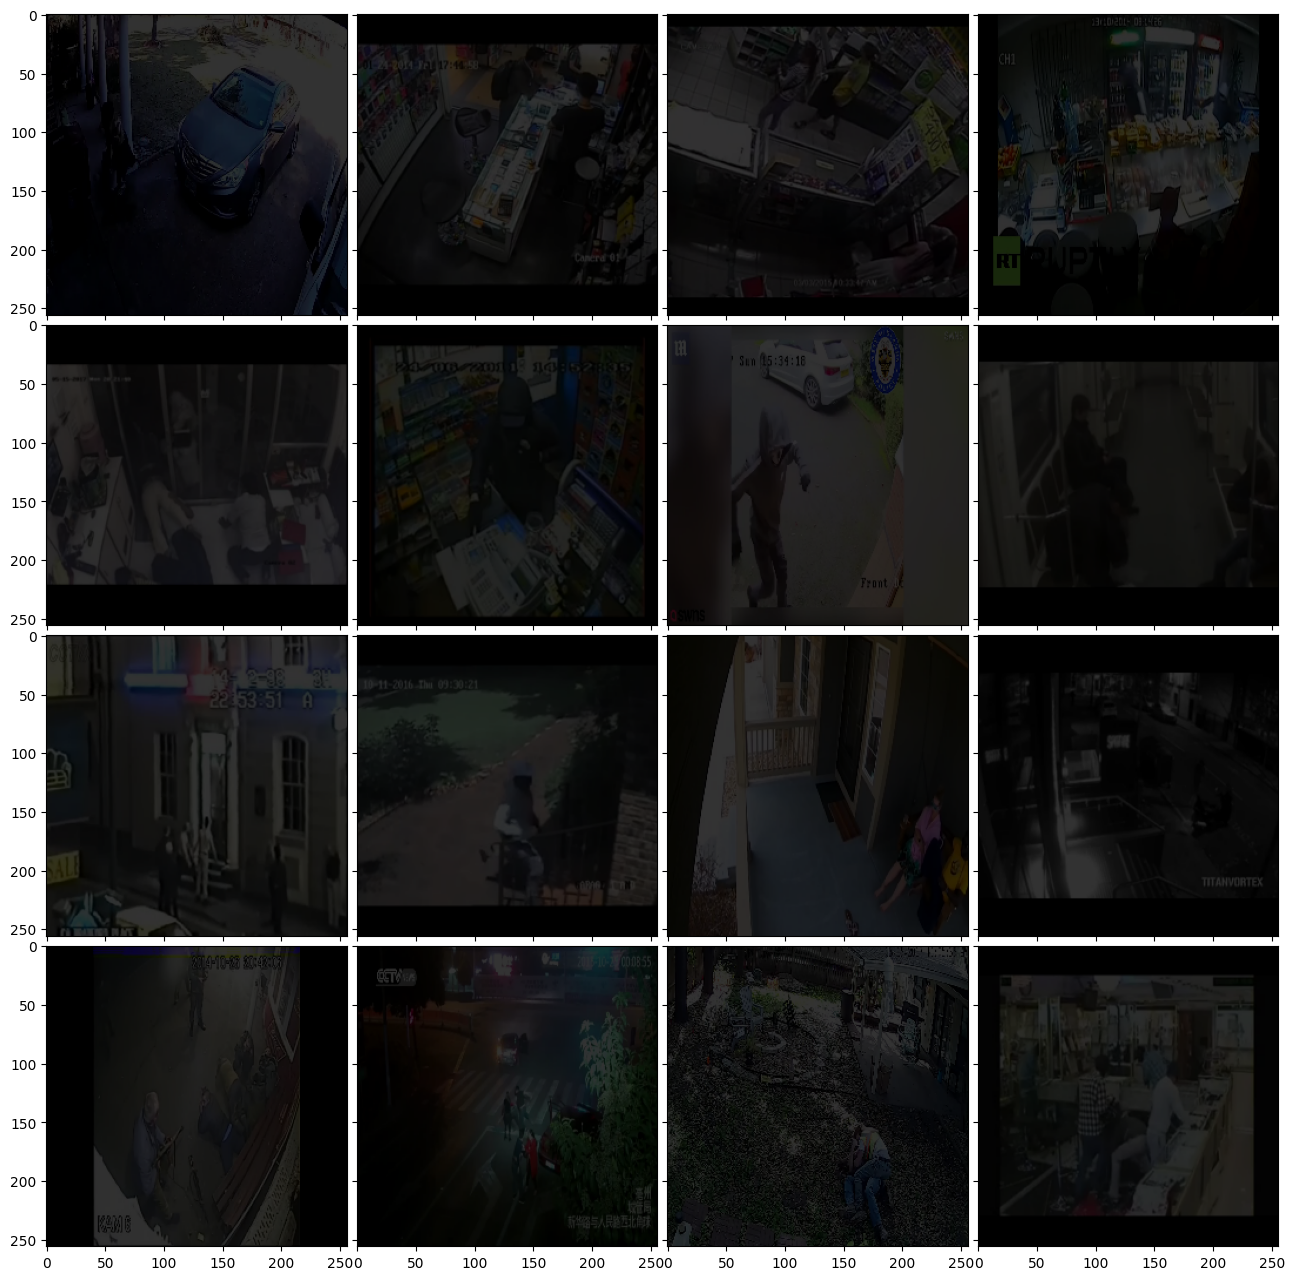

In [20]:
images = next(iter(train_dataset)).numpy()
fig = plt.figure(figsize=(16, 16))
grid = ImageGrid(fig, 111, nrows_ncols=(4, 4), axes_pad=0.1)
random_images = images[np.random.choice(np.arange(images.shape[0]), 16)]
for ax, image in zip(grid, images):
    image = image * 255.0
    ax.imshow(image.astype(np.uint8))
plt.title("Sample Images from Tiny-NeRF Data")
plt.show()


In [21]:
def build_dce_net(image_size=None) -> keras.Model:
    input_image = keras.Input(shape=[image_size, image_size, 3])
    conv1 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(input_image)
    conv2 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(conv1)
    conv3 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(conv2)
    conv4 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(conv3)
    int_con1 = layers.Concatenate(axis=-1)([conv4, conv3])
    conv5 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(int_con1)
    int_con2 = layers.Concatenate(axis=-1)([conv5, conv2])
    conv6 = layers.Conv2D(
        32, (3, 3), strides=(1, 1), activation="relu", padding="same"
    )(int_con2)
    int_con3 = layers.Concatenate(axis=-1)([conv6, conv1])
    x_r = layers.Conv2D(24, (3, 3), strides=(1, 1), activation="tanh", padding="same")(
        int_con3
    )
    return keras.Model(inputs=input_image, outputs=x_r)



In [22]:
def color_constancy_loss(x):
    mean_rgb = tf.reduce_mean(x, axis=(1, 2), keepdims=True)
    mean_red = mean_rgb[:, :, :, 0]
    mean_green = mean_rgb[:, :, :, 1]
    mean_blue = mean_rgb[:, :, :, 2]
    diff_red_green = tf.square(mean_red - mean_green)
    diff_red_blue = tf.square(mean_red - mean_blue)
    diff_green_blue = tf.square(mean_blue - mean_green)
    return tf.sqrt(
        tf.square(diff_red_green) + tf.square(diff_red_blue) + tf.square(diff_green_blue)
    )

In [23]:
def exposure_loss(x, mean_val=0.6):
    x = tf.reduce_mean(x, axis=3, keepdims=True)
    mean = tf.nn.avg_pool2d(x, ksize=16, strides=16, padding="VALID")
    return tf.reduce_mean(tf.square(mean - mean_val))

In [24]:
def illumination_smoothness_loss(x):
    """Inspired from https://github.com/tuvovan/Zero_DCE_TF/blob/master/src/loss.py#L28"""
    batch_size = tf.shape(x)[0]
    height_x = tf.shape(x)[1]
    width_x = tf.shape(x)[2]
    count_height = (tf.shape(x)[2] - 1) * tf.shape(x)[3]
    count_width = tf.shape(x)[2] * (tf.shape(x)[3] - 1)
    height_total_variance = tf.reduce_sum(
        tf.square((x[:, 1:, :, :] - x[:, : height_x - 1, :, :]))
    )
    width_total_variance = tf.reduce_sum(
        tf.square((x[:, :, 1:, :] - x[:, :, : width_x - 1, :]))
    )
    batch_size = tf.cast(batch_size, dtype=tf.float32)
    count_height = tf.cast(count_height, dtype=tf.float32)
    count_width = tf.cast(count_width, dtype=tf.float32)
    return 2 * (
        height_total_variance / count_height + width_total_variance / count_width
    ) / batch_size


In [25]:
class SpatialConsistencyLoss(losses.Loss):
    def __init__(self, **kwargs):
        super(SpatialConsistencyLoss, self).__init__(reduction="none")

        self.left_kernel = tf.constant(
            [[[[0, 0, 0]], [[-1, 1, 0]], [[0, 0, 0]]]], dtype=tf.float32
        )
        self.right_kernel = tf.constant(
            [[[[0, 0, 0]], [[0, 1, -1]], [[0, 0, 0]]]], dtype=tf.float32
        )
        self.up_kernel = tf.constant(
            [[[[0, -1, 0]], [[0, 1, 0]], [[0, 0, 0]]]], dtype=tf.float32
        )
        self.down_kernel = tf.constant(
            [[[[0, 0, 0]], [[0, 1, 0]], [[0, -1, 0]]]], dtype=tf.float32
        )

    def call(self, y_true, y_pred):

        original_mean = tf.reduce_mean(y_true, 3, keepdims=True)
        enhanced_mean = tf.reduce_mean(y_pred, 3, keepdims=True)
        original_pool = tf.nn.avg_pool2d(
            original_mean, ksize=4, strides=4, padding="VALID"
        )
        enhanced_pool = tf.nn.avg_pool2d(
            enhanced_mean, ksize=4, strides=4, padding="VALID"
        )

        d_original_left = tf.nn.conv2d(
            original_pool, self.left_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_original_right = tf.nn.conv2d(
            original_pool, self.right_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_original_up = tf.nn.conv2d(
            original_pool, self.up_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_original_down = tf.nn.conv2d(
            original_pool, self.down_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )

        d_enhanced_left = tf.nn.conv2d(
            enhanced_pool, self.left_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_enhanced_right = tf.nn.conv2d(
            enhanced_pool, self.right_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_enhanced_up = tf.nn.conv2d(
            enhanced_pool, self.up_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )
        d_enhanced_down = tf.nn.conv2d(
            enhanced_pool, self.down_kernel, strides=[1, 1, 1, 1], padding="SAME"
        )

        d_left = tf.square(d_original_left - d_enhanced_left)
        d_right = tf.square(d_original_right - d_enhanced_right)
        d_up = tf.square(d_original_up - d_enhanced_up)
        d_down = tf.square(d_original_down - d_enhanced_down)
        return d_left + d_right + d_up + d_down



In [26]:
class ZeroDCE(keras.Model):
    def __init__(self, **kwargs):
        super(ZeroDCE, self).__init__(**kwargs)
        self.dce_model = build_dce_net()

    def compile(self, learning_rate, **kwargs):
        super(ZeroDCE, self).compile(**kwargs)
        self.optimizer = optimizers.Adam(learning_rate=learning_rate)
        self.spatial_constancy_loss = SpatialConsistencyLoss(reduction="none")
    
    def summary(self, *args, **kwargs):
        self.dce_model.summary(*args, **kwargs)

    def get_enhanced_image(self, data, output):
        x = data
        for i in range(0, 3 * 8, 3):
            r = output[:, :, :, i: i + 3]
            x = x + r * (tf.square(x) - x)
        return x

    def call(self, data):
        dce_net_output = self.dce_model(data)
        return self.get_enhanced_image(data, dce_net_output)

    def compute_losses(self, data, output):
        enhanced_image = self.get_enhanced_image(data, output)
        loss_illumination = 200 * illumination_smoothness_loss(output)
        loss_spatial_constancy = tf.reduce_mean(
            self.spatial_constancy_loss(enhanced_image, data)
        )
        loss_color_constancy = 5 * tf.reduce_mean(color_constancy_loss(enhanced_image))
        loss_exposure = 10 * tf.reduce_mean(exposure_loss(enhanced_image))
        total_loss = (
            loss_illumination
            + loss_spatial_constancy
            + loss_color_constancy
            + loss_exposure
        )
        return {
            "total_loss": total_loss,
            "illumination_smoothness_loss": loss_illumination,
            "spatial_constancy_loss": loss_spatial_constancy,
            "color_constancy_loss": loss_color_constancy,
            "exposure_loss": loss_exposure,
        }

    def train_step(self, data):
        with tf.GradientTape() as tape:
            output = self.dce_model(data)
            losses = self.compute_losses(data, output)
        gradients = tape.gradient(
            losses["total_loss"], self.dce_model.trainable_weights
        )
        self.optimizer.apply_gradients(zip(gradients, self.dce_model.trainable_weights))
        return losses

    def test_step(self, data):
        output = self.dce_model(data)
        return self.compute_losses(data, output)

    def save_weights(self, filepath, overwrite=True, save_format=None, options=None):
        """While saving the weights, we simply save the weights of the DCE-Net"""
        self.dce_model.save_weights(
            filepath, overwrite=overwrite, save_format=save_format, options=options
        )

    def load_weights(self, filepath, by_name=False, skip_mismatch=False, options=None):
        """While loading the weights, we simply load the weights of the DCE-Net"""
        self.dce_model.load_weights(
            filepath=filepath,
            by_name=by_name,
            skip_mismatch=skip_mismatch,
            options=options,
        )


In [27]:
zero_dce_model = ZeroDCE()
zero_dce_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │        896 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,248 │ conv2d[0][0]      │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │      9,248 │ conv2d_1[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │      9,248 │ conv2d_2[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None,      │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ None, 64)         │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │     18,464 │ concatenate[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, None,      │          0 │ conv2d_4[0][0],   │
│ (Concatenate)       │ None, 64)         │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, None,      │     18,464 │ concatenate_1[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, None,      │          0 │ conv2d_5[0][0],   │
│ (Concatenate)       │ None, 64)         │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, None,      │     13,848 │ concatenate_2[0]… │
│                     │ None, 24)         │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 79,416 (310.22 KB)

 Trainable params: 79,416 (310.22 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
def plot_results(images, titles, figure_size=(12, 12)):
    fig = plt.figure(figsize=figure_size)
    for i in range(len(images)):
        fig.add_subplot(1, len(images), i + 1).set_title(titles[i])
        _ = plt.imshow(images[i])
        plt.axis("off")
    plt.show()


def infer(original_image):
    image = keras.preprocessing.image.img_to_array(original_image)
    image = image[:, :, :3] if image.shape[-1] > 3 else image
    image = image.astype("float32") / 255.0
    image = np.expand_dims(image, axis=0)
    output_image = zero_dce_model(image)
    output_image = tf.cast((output_image[0, :, :, :] * 255), dtype=np.uint8)
    output_image = Image.fromarray(output_image.numpy())
    return output_image


In [29]:
import tensorflow as tf

class CustomLossStoppingCallback(tf.keras.callbacks.Callback):
    def __init__(self, min_delta=0.01, patience=5, verbose=1):
        """
        Custom callback to stop training when the loss becomes stagnant.

        Args:
        min_delta: Minimum change in loss to be considered as an improvement.
        patience: Number of epochs with stagnant loss before stopping the training.
        verbose: Verbosity mode, 1 for messages, 0 for silence.
        """
        super(CustomLossStoppingCallback, self).__init__()
        self.min_delta = min_delta  # Minimum change in loss to consider as improvement
        self.patience = patience  # How many epochs to wait before stopping when loss stagnates
        self.verbose = verbose  # Whether to print logs
        self.best_loss = None  # Track the best loss
        self.wait = 0  # Track how many epochs we've waited without improvement

    def on_epoch_end(self, epoch, logs=None):
        # Get the total loss from logs at the end of the epoch
        current_loss = logs.get("total_loss")  # This assumes 'loss' is the metric to monitor

        # If no loss value is found, raise a warning and exit
        if current_loss is None:
            print(f"Warning: 'loss' metric not found in logs. Ensure it's being logged.")
            return

        # Initialize the best loss during the first epoch
        if self.best_loss is None:
            self.best_loss = current_loss

        # Check if the current loss has improved sufficiently (by more than min_delta)
        if abs(self.best_loss - current_loss) < self.min_delta:
            # Loss hasn't improved significantly; increment the wait counter
            self.wait += 1
            if self.verbose:
                print(f"Epoch {epoch + 1}: loss has not improved more than {self.min_delta}. Waiting ({self.wait}/{self.patience})")

            # If we've waited for `patience` epochs without improvement, stop training
            if self.wait >= self.patience:
                if self.verbose:
                    print(f"Epoch {epoch + 1}: Early stopping triggered due to stagnant loss.")
                self.model.stop_training = True
        else:
            # If loss has improved, reset the wait counter and update the best loss
            self.best_loss = current_loss
            self.wait = 0

    def on_train_end(self, logs=None):
        if self.verbose and self.wait >= self.patience:
            print(f"Training stopped early after {self.wait} epochs of no improvement in loss.")

# Instantiate the custom stopping callback
custom_loss_stopping = CustomLossStoppingCallback(min_delta=0.01, patience=3, verbose=1)


In [30]:
class LogPredictionCallback(callbacks.Callback):
    
    def __init__(self, image_files, log_interval, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.image_files = image_files
        self.log_interval = log_interval
    
    def on_epoch_end(self, epoch, logs=None):
        if epoch % self.log_interval == 0: 
            for image_file in self.image_files:
                original_image = Image.open(image_file)
                enhanced_image = infer(original_image)
                plot_results(
                    [original_image, enhanced_image],
                    ["Original", "Enhanced_Image"],
                    (15, 7),
                )


Epoch 1/60


I0000 00:00:1728952908.254214     790 service.cc:145] XLA service 0x7e1c2400e200 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1728952908.254276     790 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0


 2/25 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - color_constancy_loss: 6.1849e-04 - exposure_loss: 2.8511 - illumination_smoothness_loss: 3.2033 - spatial_constancy_loss: 3.6984e-06 - total_loss: 6.0550

I0000 00:00:1728952916.726717     790 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - color_constancy_loss: 7.2271e-04 - exposure_loss: 2.7474 - illumination_smoothness_loss: 1.9401 - spatial_constancy_loss: 9.0371e-06 - total_loss: 4.6883

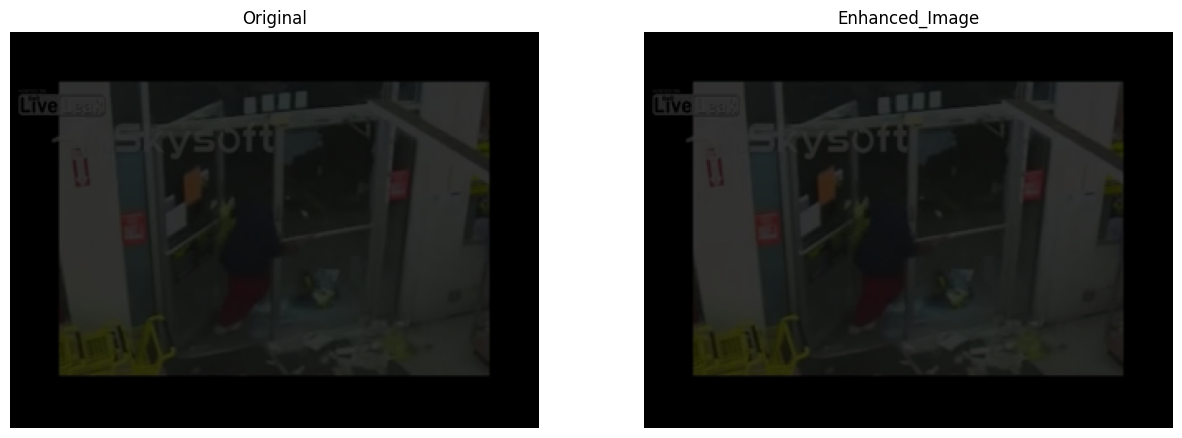

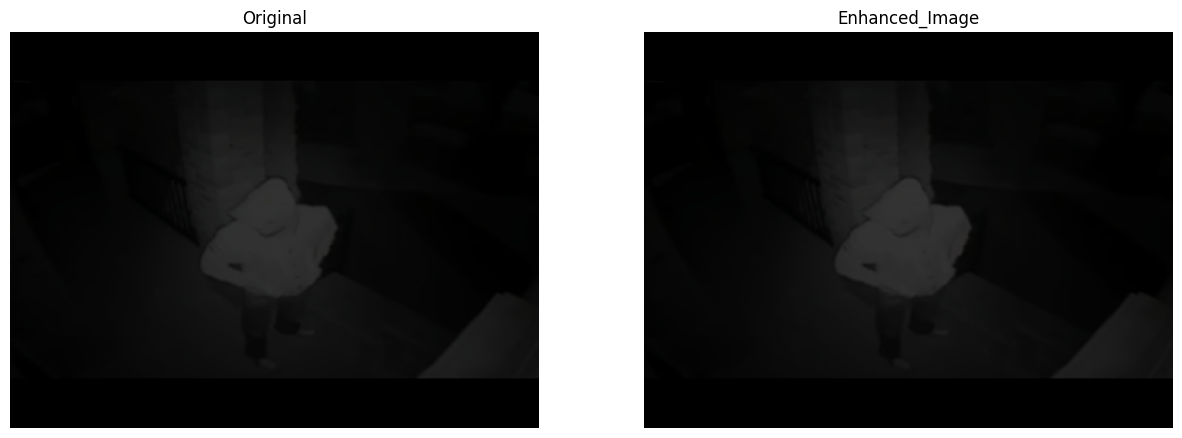

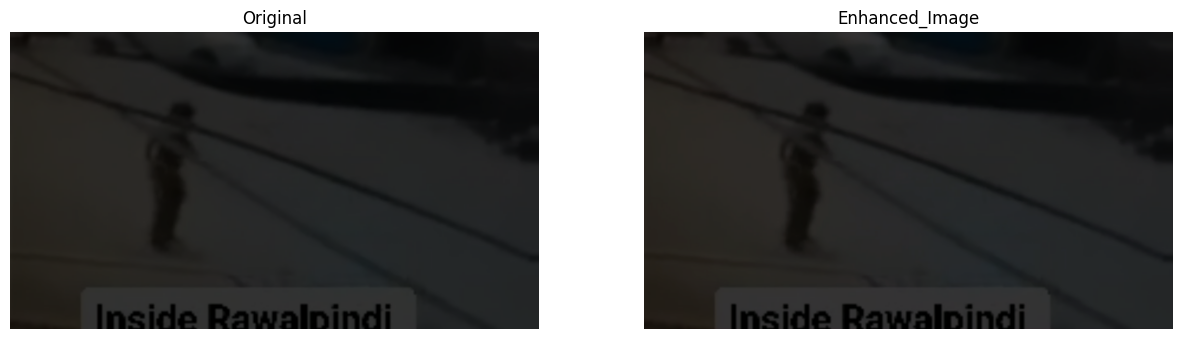

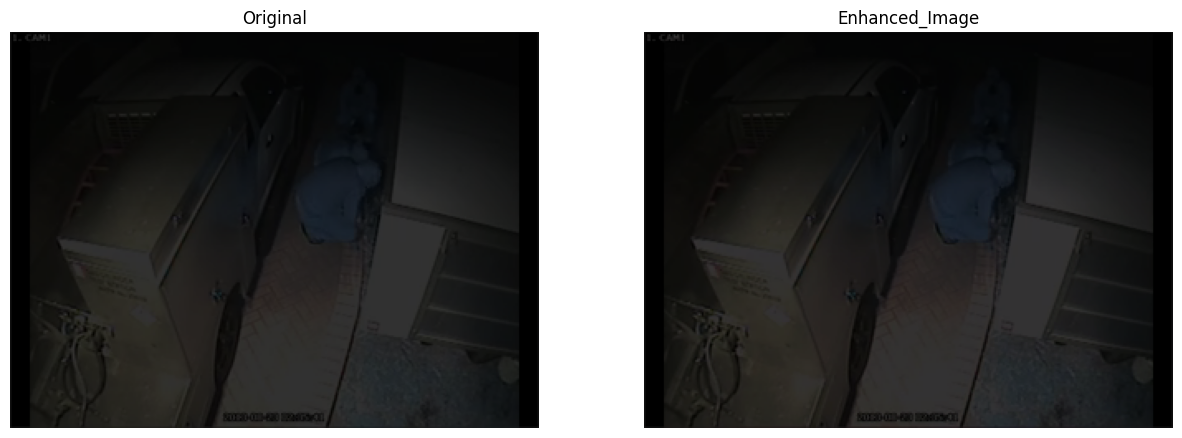

Epoch 1: loss has not improved more than 0.01. Waiting (1/3)
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 335ms/step - color_constancy_loss: 7.1447e-04 - exposure_loss: 2.7458 - illumination_smoothness_loss: 1.9121 - spatial_constancy_loss: 9.4814e-06 - total_loss: 4.6586 - val_color_constancy_loss: 7.1498e-04 - val_exposure_loss: 2.7693 - val_illumination_smoothness_loss: 0.9392 - val_spatial_constancy_loss: 1.6438e-05 - val_total_loss: 3.7093
Epoch 2/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - color_constancy_loss: 6.1358e-04 - exposure_loss: 2.7223 - illumination_smoothness_loss: 1.0655 - spatial_constancy_loss: 4.5244e-05 - total_loss: 3.7885 - val_color_constancy_loss: 7.6103e-04 - val_exposure_loss: 2.7419 - val_illumination_smoothness_loss: 0.5793 - val_spatial_constancy_loss: 6.7717e-05 - val_total_loss: 3.3220
Epoch 3/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 194ms/step - color_constancy_loss: 6.4385e-04 - exposure_loss: 2.6954 - illumination_smoothness_loss: 0.7097 - spatial_constancy_loss: 1.145

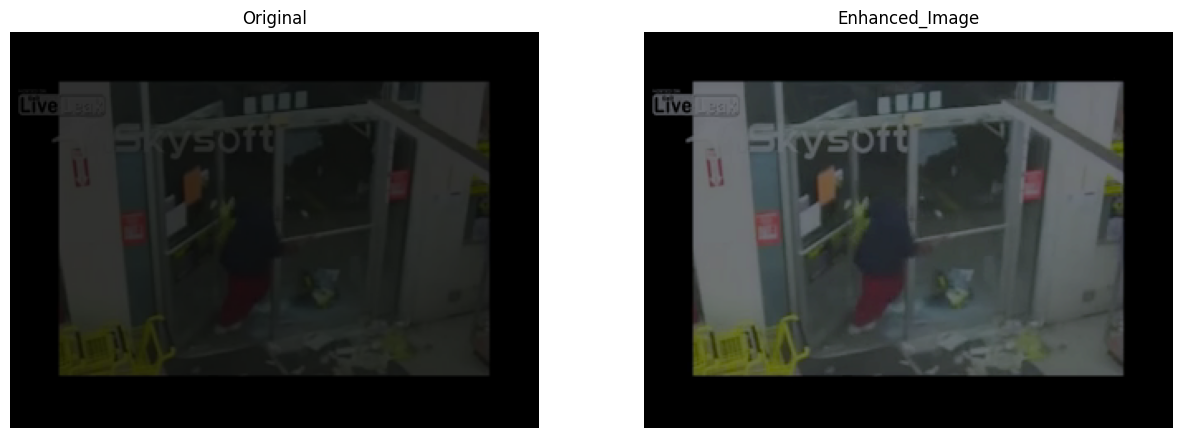

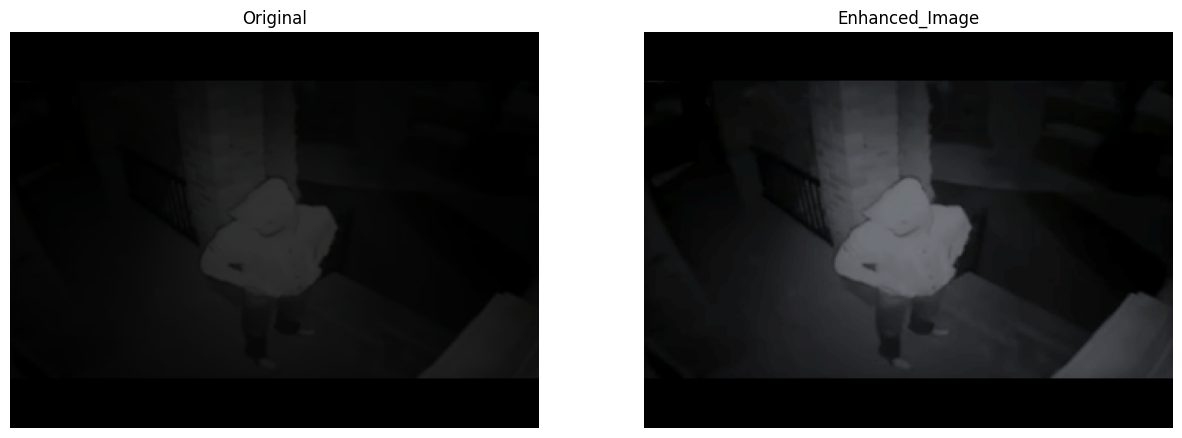

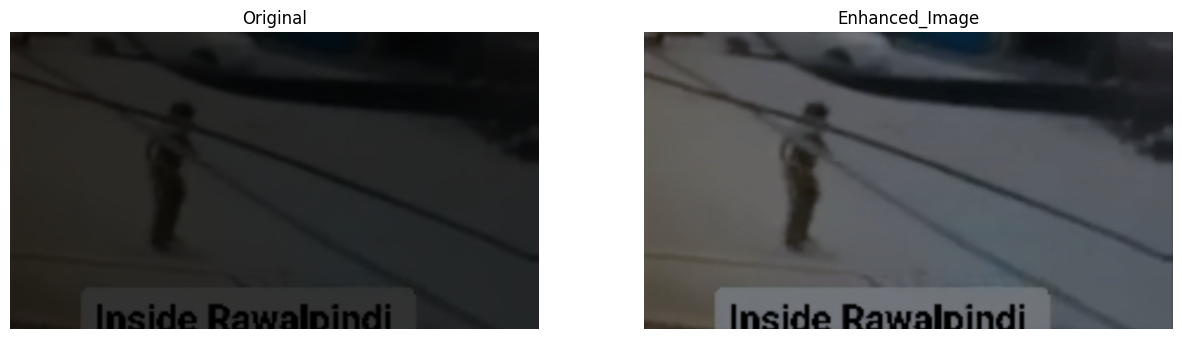

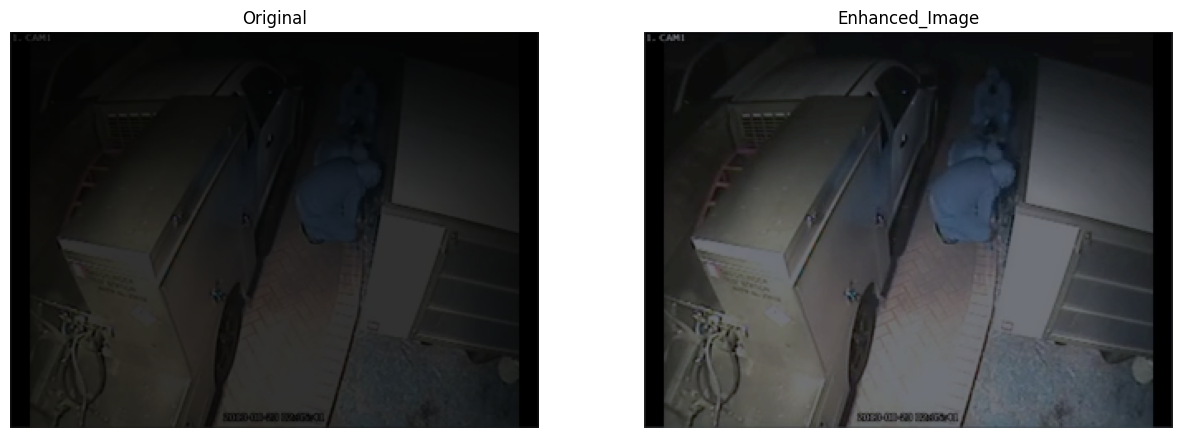

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 260ms/step - color_constancy_loss: 0.0024 - exposure_loss: 2.1046 - illumination_smoothness_loss: 0.2438 - spatial_constancy_loss: 0.0114 - total_loss: 2.3622 - val_color_constancy_loss: 0.0042 - val_exposure_loss: 1.8261 - val_illumination_smoothness_loss: 0.2558 - val_spatial_constancy_loss: 0.0245 - val_total_loss: 2.1106
Epoch 12/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 194ms/step - color_constancy_loss: 0.0081 - exposure_loss: 1.2009 - illumination_smoothness_loss: 0.3070 - spatial_constancy_loss: 0.1051 - total_loss: 1.6211 - val_color_constancy_loss: 0.0096 - val_exposure_loss: 0.7327 - val_illumination_smoothness_loss: 0.2643 - val_spatial_constancy_loss: 0.2163 - val_total_loss: 1.2229
Epoch 13/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 185ms/step - color_constancy_loss: 0.0091 - exposure_loss: 0.6937 - illumination_smoothness_loss: 0.2370 - spatial_constancy_loss: 0.2366 - total_loss: 1.1764 - val_color_constancy_loss: 0.0076 - val_exposure_loss: 0.7383 - val_illu

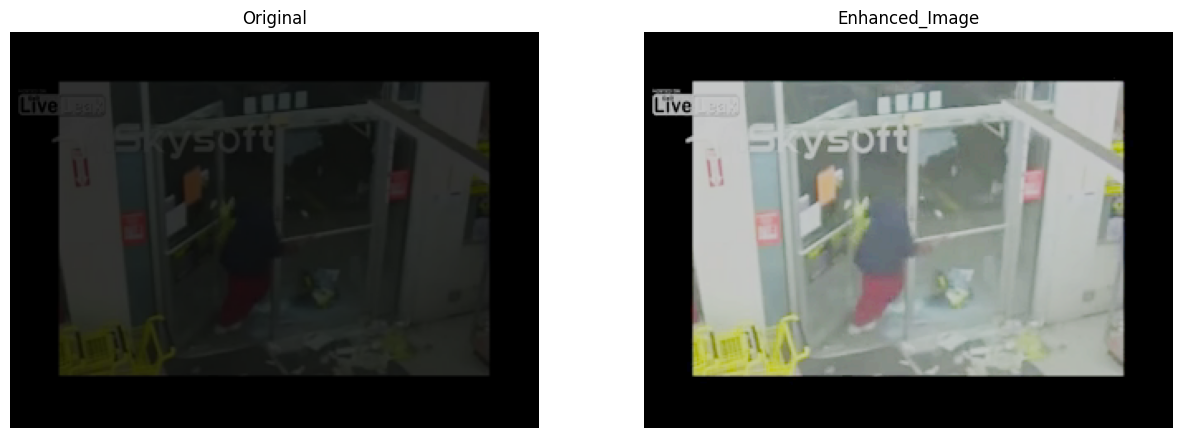

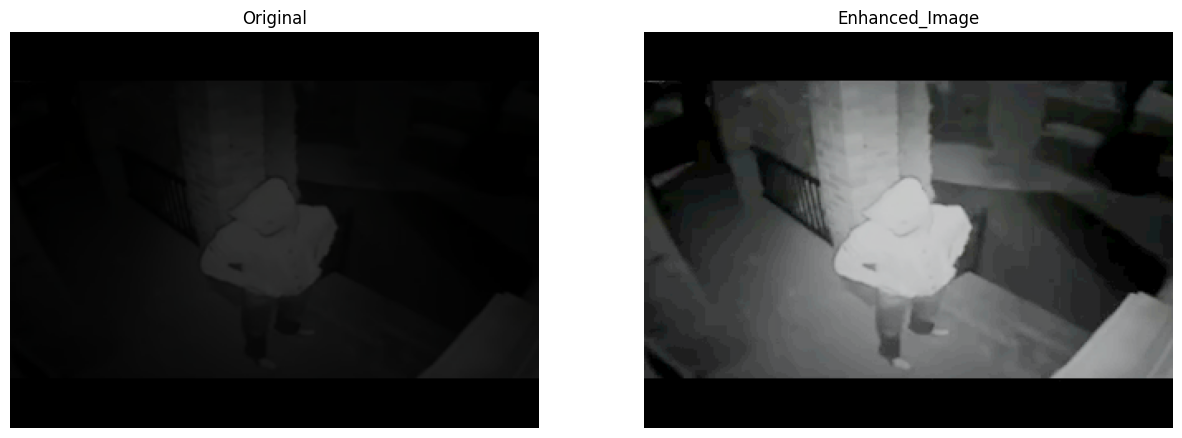

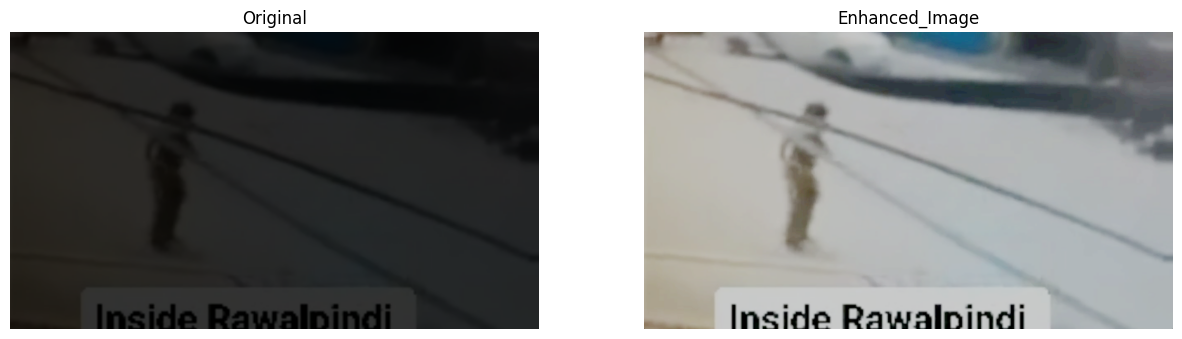

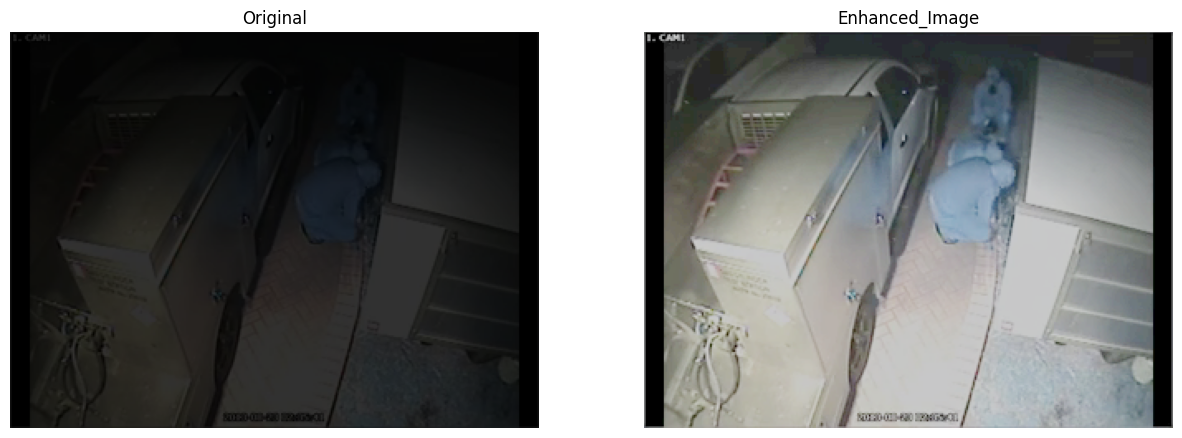

Epoch 21: loss has not improved more than 0.01. Waiting (1/3)
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 258ms/step - color_constancy_loss: 0.0087 - exposure_loss: 0.6868 - illumination_smoothness_loss: 0.1131 - spatial_constancy_loss: 0.2393 - total_loss: 1.0479 - val_color_constancy_loss: 0.0078 - val_exposure_loss: 0.7131 - val_illumination_smoothness_loss: 0.0987 - val_spatial_constancy_loss: 0.2231 - val_total_loss: 1.0427
Epoch 22/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 195ms/step - color_constancy_loss: 0.0087 - exposure_loss: 0.6858 - illumination_smoothness_loss: 0.1073 - spatial_constancy_loss: 0.2399 - total_loss: 1.0417 - val_color_constancy_loss: 0.0078 - val_exposure_loss: 0.7116 - val_illumination_smoothness_loss: 0.0938 - val_spatial_constancy_loss: 0.2239 - val_total_loss: 1.0370
Epoch 23/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - color_constancy_loss: 0.0087 - exposure_loss: 0.6826 - illumination_smoothness_loss: 0.1023 - spatial_constancy_loss: 0.2404 - total_loss: 1.0340Epoch 23: los

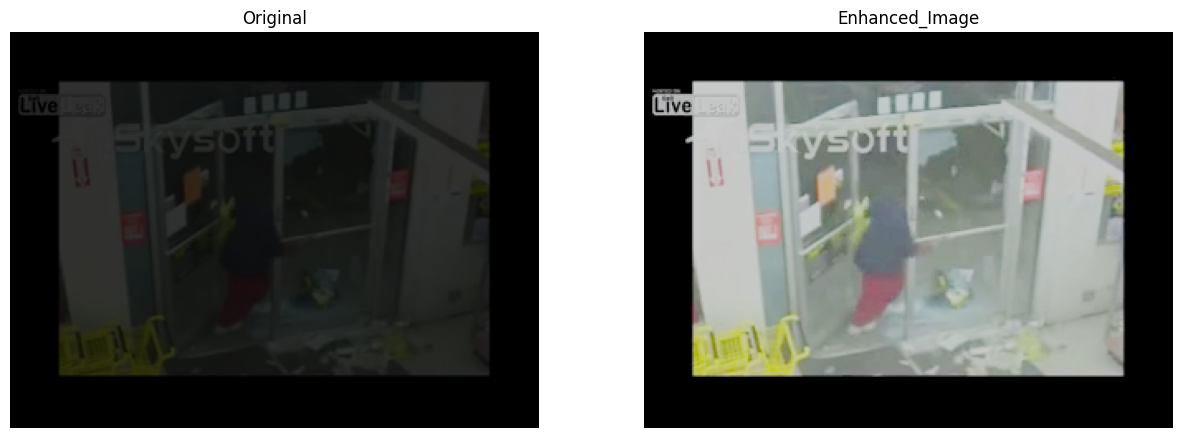

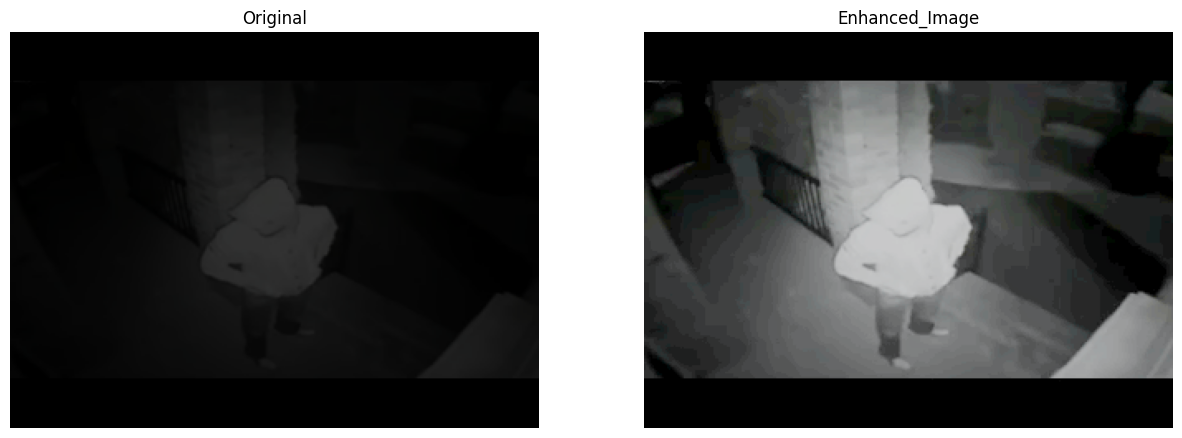

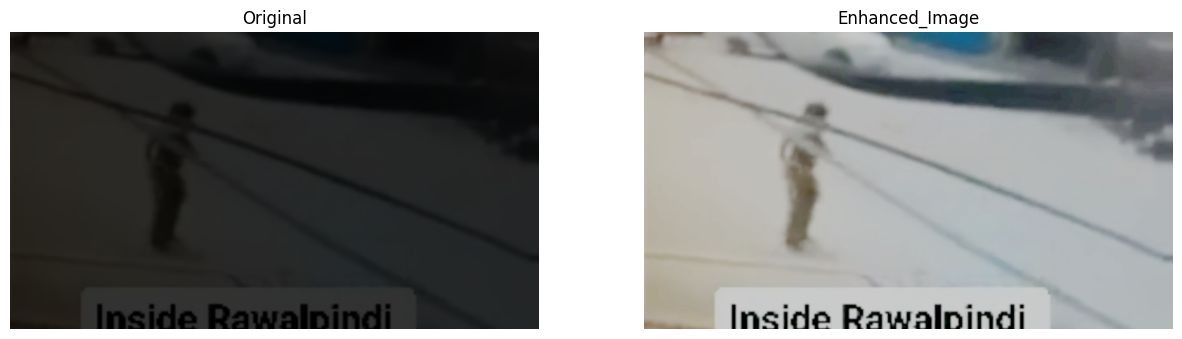

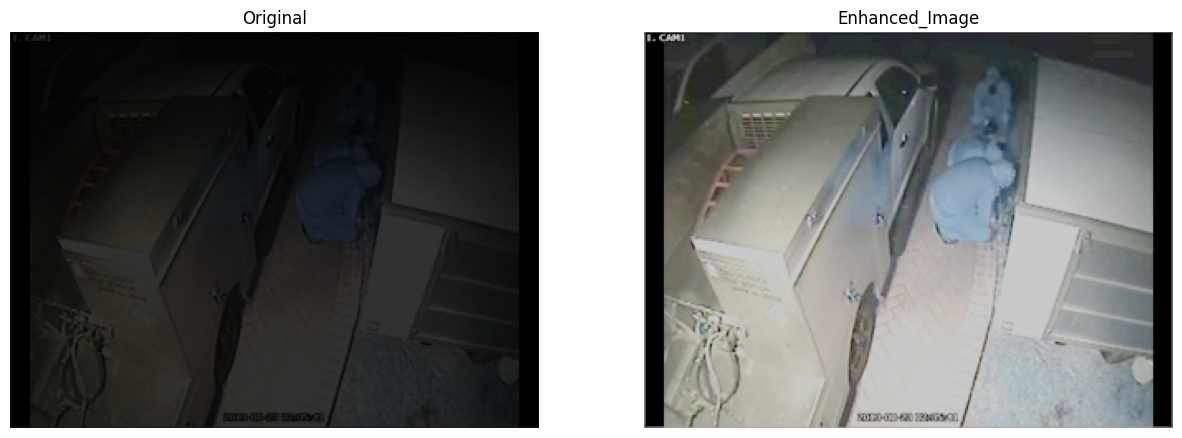

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 263ms/step - color_constancy_loss: 0.0087 - exposure_loss: 0.6787 - illumination_smoothness_loss: 0.0688 - spatial_constancy_loss: 0.2446 - total_loss: 1.0009 - val_color_constancy_loss: 0.0078 - val_exposure_loss: 0.7036 - val_illumination_smoothness_loss: 0.0607 - val_spatial_constancy_loss: 0.2284 - val_total_loss: 1.0004
Epoch 32/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - color_constancy_loss: 0.0088 - exposure_loss: 0.6758 - illumination_smoothness_loss: 0.0657 - spatial_constancy_loss: 0.2450 - total_loss: 0.9952Epoch 32: loss has not improved more than 0.01. Waiting (1/3)
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 184ms/step - color_constancy_loss: 0.0088 - exposure_loss: 0.6781 - illumination_smoothness_loss: 0.0654 - spatial_constancy_loss: 0.2451 - total_loss: 0.9973 - val_color_constancy_loss: 0.0078 - val_exposure_loss: 0.7028 - val_illumination_smoothness_loss: 0.0578 - val_spatial_constancy_loss: 0.2288 - val_total_loss: 0.9972
Epoch 33/60
25/25 ━━━━━━━

In [31]:
zero_dce_model.compile(learning_rate=LEARNING_RATE)

history = zero_dce_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[
        LogPredictionCallback(
            image_files=random.sample(val_image_files, 4),
            log_interval=LOG_INTERVALS
        ), custom_loss_stopping
    ]
)

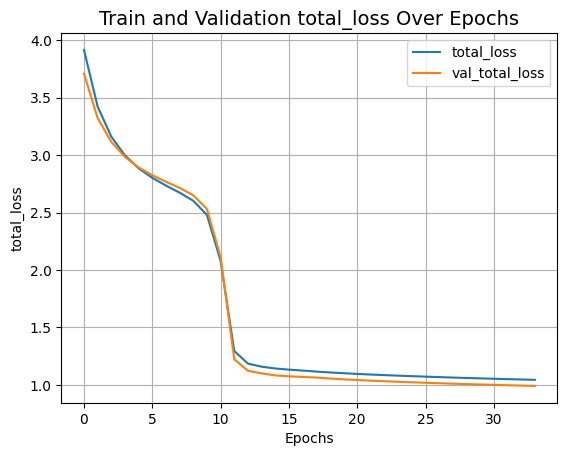

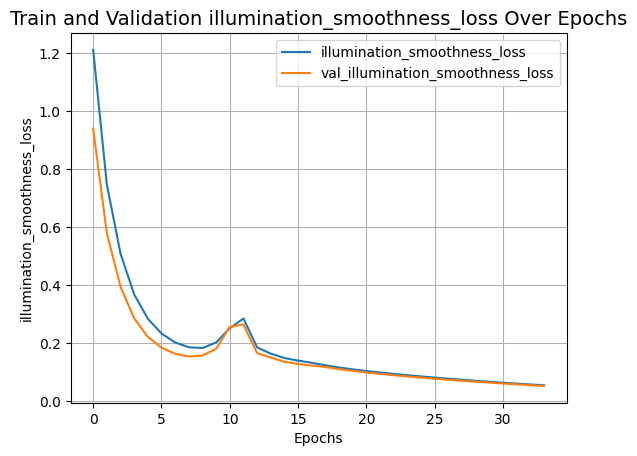

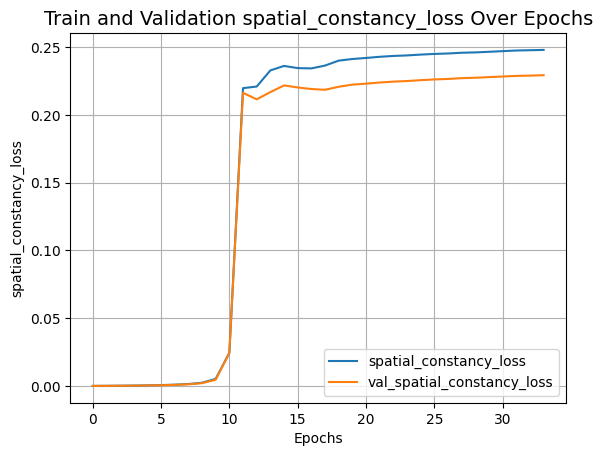

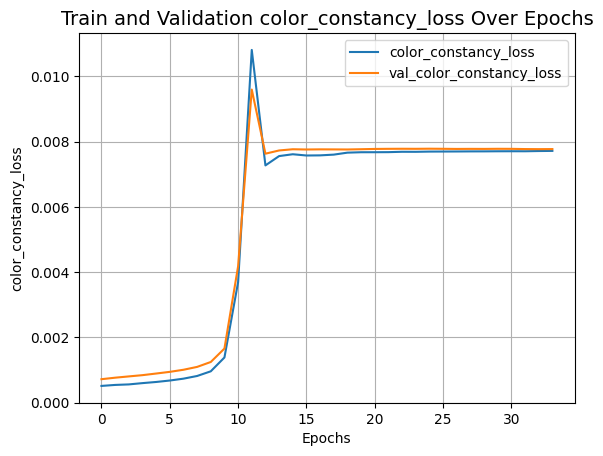

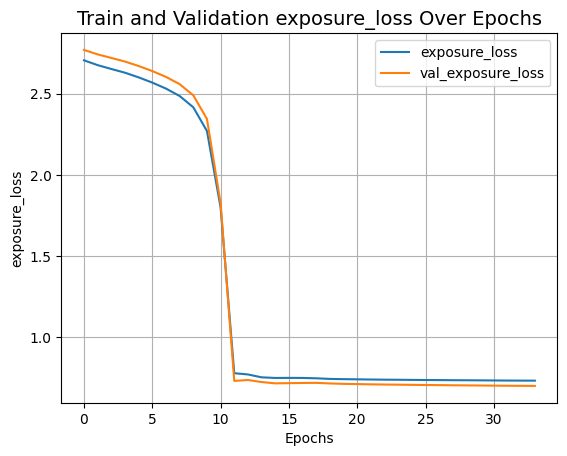

In [32]:
def plot_result(item):
    plt.plot(history.history[item], label=item)
    plt.plot(history.history["val_" + item], label="val_" + item)
    plt.xlabel("Epochs")
    plt.ylabel(item)
    plt.title("Train and Validation {} Over Epochs".format(item), fontsize=14)
    plt.legend()
    plt.grid()
    plt.show()


plot_result("total_loss")
plot_result("illumination_smoothness_loss")
plot_result("spatial_constancy_loss")
plot_result("color_constancy_loss")
plot_result("exposure_loss")

In [33]:
'''for image_file in test_image_files:
    original_image = Image.open(image_file)
    enhanced_image = infer(original_image)
    plot_results(
        [original_image, ImageOps.autocontrast(original_image), enhanced_image],
        ["Original", "PIL Autocontrast", "Enhanced_Image"],
        (20, 12),
    )'''

'for image_file in test_image_files:\n    original_image = Image.open(image_file)\n    enhanced_image = infer(original_image)\n    plot_results(\n        [original_image, ImageOps.autocontrast(original_image), enhanced_image],\n        ["Original", "PIL Autocontrast", "Enhanced_Image"],\n        (20, 12),\n    )'

In [ ]:
'''exampleInference ='/kaggle/input/cctv-action-recognition-dataset/Videos/Videos/grab/UCFCRIME_Burglary023_grab_1.mp4'''

In [ ]:
'''import cv2
import os

# Create a list to store the extracted frames
frames_list = []

# Open the video using OpenCV
cap = cv2.VideoCapture(exampleInference)

# Get the total number of frames in the video
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Calculate the frame interval (divide the total frames by 20)
frame_interval = total_frames // 20

# Loop through the video and extract 20 frames
for i in range(20):
    # Set the position of the next frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, i * frame_interval)
    
    # Read the frame
    ret, frame = cap.read()
    
    # If frame is read correctly, append it to the list
    if ret:
        frames_list.append(frame)
    else:
        print(f"Could not read frame at index {i * frame_interval}")

# Release the video capture object
cap.release()

for original_image in frames_list:
    enhanced_image = infer(original_image)
    plot_results(
        [original_image, ImageOps.autocontrast(Image.fromarray(np.array(original_image)[:, :, :3])), enhanced_image],
        ["Original", "PIL Autocontrast", "Enhanced"],
        (30, 22),
    )

'''

# Enhancement of Video Frames

In [34]:
def is_low_light(image, threshold=60):
    '''
    Determines if an image is taken in low light
    
    image: np array or cv2 image
    '''
    # Convert the image to grayscale to calculate brightness
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Calculate the average brightness of the image
    avg_brightness = np.mean(gray_image)
    
    # Check if the average brightness is below the threshold
    return avg_brightness < threshold

def enhance_if_low_light(image):
    '''
    enhances the image if it is taken in low light
    
    image: np array or cv2 image
    '''
    if is_low_light(image):
        enhanced_image = infer(image)
        return enhanced_image
    else:
        return image

In [35]:
def enhance_video(input_video_path, output_video_path):
    cap = cv2.VideoCapture(input_video_path)

    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for mp4 format

    out = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))
    !cd /kaggle/working/ && mkdir enh_frames
    
    cnt = 1

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Apply the enhance function to the frame (assuming enhance_function is provided)
        enhanced_frame = enhance_if_low_light(frame)
        cv2.imwrite(f'/kaggle/working/enh_frames/{cnt}.png',enhanced_frame)
        # Write the enhanced frame to the output video
        out.write(enhanced_frame)
        cnt+=1
    # Release the video objects
    cap.release()
    out.release()

## def enhance_video(input_video_path, output_video_path):
    cap = cv2.VideoCapture(input_video_path)

    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for mp4 format

    out = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))
    !cd /kaggle/working/ && mkdir enh_frames
    
    cnt = 1

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Apply the enhance function to the frame (assuming enhance_function is provided)
        enhanced_frame = enhance_if_low_light(frame)
        cv2.imwrite(f'/kaggle/working/enh_frames/{cnt}.png',enhanced_frame)
        # Write the enhanced frame to the output video
        out.write(enhanced_frame)
        cnt+=1
    # Release the video objects
    cap.release()
    out.release()

# Frontality Evaluation using Mediapipe


In [115]:
!conda deactivate
!pip install -q mediapipe


CondaError: Run 'conda init' before 'conda deactivate'



In [116]:
def frontalityInstallations():
    !cd /kaggle/working/ && wget -O face_landmarker_v2_with_blendshapes.task -q https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task
    

In [117]:
#@markdown We implemented some functions to visualize the face landmark detection results. <br/> Run the following cell to activate the functions.

from mediapipe import solutions
from mediapipe.framework.formats import landmark_pb2
import numpy as np
import matplotlib.pyplot as plt
import cv2

def draw_landmarks_on_image(rgb_image, detection_result):
  face_landmarks_list = detection_result.face_landmarks
  annotated_image = np.copy(rgb_image)

  # Loop through the detected faces to visualize.
  for idx in range(len(face_landmarks_list)):
    face_landmarks = face_landmarks_list[idx]

    # Draw the face landmarks.
    face_landmarks_proto = landmark_pb2.NormalizedLandmarkList()
    face_landmarks_proto.landmark.extend([
      landmark_pb2.NormalizedLandmark(x=landmark.x, y=landmark.y, z=landmark.z) for landmark in face_landmarks
    ])

    solutions.drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks_proto,
        connections=mp.solutions.face_mesh.FACEMESH_TESSELATION,
        landmark_drawing_spec=None,
        connection_drawing_spec=mp.solutions.drawing_styles
        .get_default_face_mesh_tesselation_style())
    solutions.drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks_proto,
        connections=mp.solutions.face_mesh.FACEMESH_CONTOURS,
        landmark_drawing_spec=None,
        connection_drawing_spec=mp.solutions.drawing_styles
        .get_default_face_mesh_contours_style())
    solutions.drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks_proto,
        connections=mp.solutions.face_mesh.FACEMESH_IRISES,
          landmark_drawing_spec=None,
          connection_drawing_spec=mp.solutions.drawing_styles
          .get_default_face_mesh_iris_connections_style())

  return annotated_image

def plot_face_blendshapes_bar_graph(face_blendshapes):
  # Extract the face blendshapes category names and scores.
  face_blendshapes_names = [face_blendshapes_category.category_name for face_blendshapes_category in face_blendshapes]
  face_blendshapes_scores = [face_blendshapes_category.score for face_blendshapes_category in face_blendshapes]
  # The blendshapes are ordered in decreasing score value.
  face_blendshapes_ranks = range(len(face_blendshapes_names))

  fig, ax = plt.subplots(figsize=(12, 12))
  bar = ax.barh(face_blendshapes_ranks, face_blendshapes_scores, label=[str(x) for x in face_blendshapes_ranks])
  ax.set_yticks(face_blendshapes_ranks, face_blendshapes_names)
  ax.invert_yaxis()

  # Label each bar with values
  for score, patch in zip(face_blendshapes_scores, bar.patches):
    plt.text(patch.get_x() + patch.get_width(), patch.get_y(), f"{score:.4f}", va="top")

  ax.set_xlabel('Score')
  ax.set_title("Face Blendshapes")
  plt.tight_layout()
  plt.show()

In [118]:
# @markdown The parameter C controls the permissible roll and yaw angles
C = 60 #@param
def calc_frontality(landmarks):
    forehead_idx = 10
    chin_idx = 152
    left_eye_idx = 33
    right_eye_idx = 263
  # Extract landmark coordinates
    forehead = landmarks[forehead_idx]
    chin = landmarks[chin_idx]
    left_eye = landmarks[left_eye_idx]
    right_eye = landmarks[right_eye_idx]

  # Calculate Yaw (left-right rotation, horizontal plane)
    yaw = np.arctan2(right_eye.z - left_eye.z, right_eye.x - left_eye.x)

  # Calculate Pitch (up-down rotation, vertical plane)
    pitch = np.arctan2(forehead.z-chin.z, chin.y - forehead.y)

  # Optionally convert from radians to degrees
    yaw_deg = np.degrees(yaw)
    pitch_deg = np.degrees(pitch)

  # Output the results
    print(f"Yaw: {yaw_deg:.2f} degrees")
    print(f"Pitch: {pitch_deg:.2f} degrees")

    frontality_score = 1 - (abs(yaw_deg) + abs(pitch_deg)) / C
    frontality_score = max(0, frontality_score)
    print(f"Frontality Score: {frontality_score}")
    return yaw_deg, pitch_deg, frontality_score

In [119]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import warnings
warnings.filterwarnings("ignore")
def get_frontality(IMAGE_FILE):
  # STEP 2: Create an FaceLandmarker object.
  base_options = python.BaseOptions(model_asset_path='/kaggle/working/face_landmarker_v2_with_blendshapes.task')
  options = vision.FaceLandmarkerOptions(base_options=base_options,
                                        output_face_blendshapes=False,
                                        output_facial_transformation_matrixes=False,
                                        num_faces=1)
  detector = vision.FaceLandmarker.create_from_options(options)

  # STEP 3: Load the input image.
  image = mp.Image.create_from_file(IMAGE_FILE)
  #image = mp.Image(image_format=mp.ImageFormat.SRGB, data=IMAGE_FILE)


  # STEP 4: Detect face landmarks from the input image.
  detection_result = detector.detect(image)

  # STEP 5: Process the detection result
  if detection_result.face_landmarks:
    yaw_deg, pitch_deg, frontality_score = calc_frontality(detection_result.face_landmarks[0])
    annotated_image = draw_landmarks_on_image(image.numpy_view(), detection_result)
    to_show = cv2.resize(annotated_image, (480,270))
    plt.imshow(cv2.cvtColor(to_show, cv2.COLOR_RGB2BGR))
    return yaw_deg, pitch_deg, frontality_score
  else:
    return None

In [120]:
#get_frontality('/kaggle/input/dweep-face/face1.png')

# Face Frontalization

In [121]:
import torch

def frontalizationInstallations():
    !cd /kaggle/working/ && git clone https://github.com/djthegr8/FFWM/
    !conda create -n newCondaEnvironment -c cctbx202208 -y
    !source /opt/conda/bin/activate newCondaEnvironment && conda install -c cctbx202208 python=3.7 -y
    !/opt/conda/envs/newCondaEnvironment/bin/python3 -m pip install --upgrade pip
    !/opt/conda/envs/newCondaEnvironment/bin/python3 -m pip install torch==1.5.0 torchvision==0.6.0
    !/opt/conda/envs/newCondaEnvironment/bin/python3 -m pip install -r /kaggle/working/FFWM/requirements.txt
    !cp -r /kaggle/input/ckpts/pytorch/default/1/checkpoints ./FFWM/
    !/opt/conda/envs/newCondaEnvironment/bin/python3 -m pip install dominate    
    !cd /kaggle/working/ &&  wget -q -O detector.tflite -q https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite

In [122]:
'''!cd ./FFWM && python test_ffwm.py \
            --dataroot /kaggle/input/frontalization-try-2-1/Frontalization_input_2 \
            --preload '''

'!cd ./FFWM && python test_ffwm.py             --dataroot /kaggle/input/frontalization-try-2-1/Frontalization_input_2             --preload '

In [123]:
import os
def save_forFrontalize(im):
    folder_path = '/kaggle/working/lfw/images'
    if not os.path.exists(folder_path):
        os.makedirs(folder_path)
        print(f"Folder '{folder_path}' created.")
    else:
        print(f"Folder '{folder_path}' already exists.")
    file_path = folder_path + '/raw_img.png'
    cv2.imwrite(file_path, im)

In [ ]:
'''!cd ./FFWM && /opt/conda/envs/newCondaEnvironment/bin/python3 test_ffwm.py --datamode lfw --dataroot /kaggle/input/frontalization-trial-1/Frontalization_input/ --preload'''

In [ ]:
'''!cd ./FFWM && /opt/conda/envs/newCondaEnvironment/bin/python3 test_ffwm.py --datamode lfw --dataroot /kaggle/working/ --preload'''

In [ ]:
'''import subprocess

def run_shell_script(script_path):
    result = subprocess.run([script_path], shell=True, capture_output=True, text=True)

    print(f"Output:\n{result.stdout}")
    print(f"Errors:\n{result.stderr}" if result.stderr else "No Errors")'''

In [81]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def crop_face(image):
    # Initialize MediaPipe Face Detection
    #mp_face_detection = mp.solutions.face_detection
    #mp_drawing = mp.solutions.drawing_utils

    #with mp_face_detection.FaceDetection(min_detection_confidence=0.5) as face_detection:
    #    # Convert the image to RGB as MediaPipe works with RGB images
    #    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Process the image and detect faces
    #    results = face_detection.process(image_rgb)
    #    
    #    if not results.detections:
    #        print("No face detected")
    #        return image  # Return original image if no face is detected
        
        # Extract the first detected face (MediaPipe can detect multiple faces)
    #    detection = results.detections[0]
        
        # Get the bounding box information
    #    bboxC = detection.location_data.relative_bounding_box
    #    ih, iw, _ = image.shape
    #    x = int(bboxC.xmin * iw)
    #    y = int(bboxC.ymin * ih)
    #    w = int(bboxC.width * iw)
    #    h = int(bboxC.height * ih)
    base_options = python.BaseOptions(model_asset_path = 'detector.tflite')
    options = vision.FaceDetectorOptions(base_options = base_options)
    detector = vision.FaceDetector.create_from_options(options)
    image = mp.Image.create_from_file(image_path)
    detection_result = detector.detect(image)
    bb = detection_result.detections[0].bounding_box
    x, y, w, h = bb.origin_x, bb.origin_y, bb.width, bb.height
    
        # Crop the face from the image
    try:
            face_image = image[y-75:y + h+50, x-75:x + w+75]
            return face_image
    except:
            face_image = image[y:y + h, x:x + w]

def resize_and_pad(image):
    target_size=(128, 128)
    
    # First, crop the image to the detected face
    face_image = crop_face(image)
    
    # Get dimensions of the cropped image
    h, w = face_image.shape[:2]

    # Calculate the aspect ratio
    aspect_ratio = w / h

    # Determine the target dimensions while maintaining the aspect ratio
    if aspect_ratio > 1:
        # Wider image
        new_w = target_size[0]
        new_h = int(target_size[0] / aspect_ratio)
    else:
        # Taller image
        new_h = target_size[1]
        new_w = int(target_size[1] * aspect_ratio)

    # Resize the image with the new dimensions
    resized_image = cv2.resize(face_image, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # Create a white canvas of the target size
    padded_image = np.ones((target_size[1], target_size[0], 3), dtype=np.uint8) * 255

    # Calculate the top-left corner for centering the resized image
    x_offset = (target_size[0] - new_w) // 2
    y_offset = (target_size[1] - new_h) // 2

    # Place the resized image on the canvas
    padded_image[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized_image

    return padded_image

In [ ]:
'''import numpy as np
import cv2
pth = '/kaggle/input/dweep-face/face1.png'
#pth = '/kaggle/input/frontalization-trial-1/Frontalization_input/lfw/images/George_Clooney_0002.png'
im = cv2.imread(pth)'''

In [103]:
def frontalize(im):
    preprocessedImg = resize_and_pad(im)
    save_forFrontalize(preprocessedImg)
    !cd /kaggle/working/FFWM && /opt/conda/envs/newCondaEnvironment/bin/python3 test_ffwm.py --datamode lfw --dataroot /kaggle/working/ --preload

    folder_path = '/kaggle/working/FFWM/checkpoints/ffwm/test/lfw/'
    uid = [f.split('_img_F')[0] for f in os.listdir(folder_path) if '_img_F' in f][0]
    img2_path = os.path.join(folder_path, f"{uid}_fake_F128.png")
    
    return img2_path


In [ ]:
'''pth2 = frontalize(im)'''

In [ ]:
'''plt.imshow(cv2.cvtColor(cv2.imread(pth2), cv2.COLOR_BGR2RGB))'''

# Frontal Face Reconstruction

In [104]:
def reconstrucInstallations():
    !cd /kaggle/working/
    !conda create -n ffRec -c cctbx202208 -y
    !source /opt/conda/bin/activate ffRec && conda install -c cctbx202208 python=3.7 -y
    !/opt/conda/envs/ffRec/bin/python3 -m pip install --upgrade pip
    # Clone GFPGAN and enter the GFPGAN folder
    !rm -rf GFPGAN
    !git clone https://github.com/TencentARC/GFPGAN.git
    %cd GFPGAN

# Set up the environment
# Install basicsr - https://github.com/xinntao/BasicSR
# We use BasicSR for both training and inference
    !/opt/conda/envs/ffRec/bin/python3 -m pip install basicsr
# Install facexlib - https://github.com/xinntao/facexlib
# We use face detection and face restoration helper in the facexlib package
    !/opt/conda/envs/ffRec/bin/python3 -m pip install facexlib
# Install other depencencies
    !/opt/conda/envs/ffRec/bin/python3 -m pip install -r requirements.txt
    !/opt/conda/envs/ffRec/bin/python3 setup.py develop
    !/opt/conda/envs/ffRec/bin/python3 -m pip install realesrgan  # used for enhancing the background (non-face) regions
# Download the pre-trained model
# !wget https://github.com/TencentARC/GFPGAN/releases/download/v0.2.0/GFPGANCleanv1-NoCE-C2.pth -P experiments/pretrained_models
# Now we use the V1.3 model for the demo
    !wget https://github.com/TencentARC/GFPGAN/releases/download/v1.3.0/GFPGANv1.3.pth -P experiments/pretrained_models
    !/opt/conda/envs/ffRec/bin/python3 -m pip install --upgrade torchvision typing_extensions
    %cd /kaggle/working/GFPGAN
    %cd /kaggle/working
    

In [ ]:
'''import shutil
import os
upload_folder = 'inputs/upload'

if os.path.isdir(upload_folder):
    shutil.rmtree(upload_folder)
os.makedirs(upload_folder, exist_ok=True)
shutil.move('inputs/whole_imgs/Blake_Lively.jpg', 'inputs/upload/Blake_Lively.jpg')'''

In [105]:
# Now we use the GFPGAN to restore the above low-quality images
# We use [Real-ESRGAN](https://github.com/xinntao/Real-ESRGAN) for enhancing the background (non-face) regions
# You can find the different models in https://github.com/TencentARC/GFPGAN#european_castle-model-zoo
import glob
def reconstruct(path):
    !rm -rf results
    !/opt/conda/envs/ffRec/bin/python3 inference_gfpgan.py -i {path} -o results -v 1.3 -s 2 --bg_upsampler realesrgan
    result_folder = 'results/restored_faces'
    output_list = sorted(glob.glob(os.path.join(result_folder, '*')))
    print(output_list)
    !ls results/cmp
    %cd /kaggle/working
    return '/kaggle/working/GFPGAN/' + output_list[0]
# Usage: python inference_gfpgan.py -i inputs/whole_imgs -o results -v 1.3 -s 2 [options]...
# 
#  -h                   show this help
#  -i input             Input image or folder. Default: inputs/whole_imgs
#  -o output            Output folder. Default: results
#  -v version           GFPGAN model version. Option: 1 | 1.2 | 1.3. Default: 1.3
#  -s upscale           The final upsampling scale of the image. Default: 2
#  -bg_upsampler        background upsampler. Default: realesrgan
#  -bg_tile             Tile size for background sampler, 0 for no tile during testing. Default: 400
#  -suffix              Suffix of the restored faces
#  -only_center_face    Only restore the center face
#  -aligned             Input are aligned faces
#  -ext                 Image extension. Options: auto | jpg | png, auto means using the same extension as inputs. Default: auto



# YOLO-DeepSort

In [106]:
def yoloInstallations():
    %cd /kaggle/working
    !git clone https://github.com/djthegr8/YOLOv10_DeepSORT/
    %cd YOLOv10_DeepSORT
    !git pull 
    !conda env create -f conda.yml
    !source /opt/conda/bin/activate yolov10-deepsort
    ! mkdir -p weights
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10n.pt
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10s.pt
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10m.pt
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10b.pt
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10x.pt
    ! wget -P weights -q https://github.com/jameslahm/yolov10/releases/download/v1.0/yolov10l.pt
    ! ls -lh weights
    !/opt/conda/envs/yolov10-deepsort/bin/python3 -m pip install huggingface_hub

In [40]:
'''yoloInstallations()'''

'yoloInstallations()'

In [50]:
'''import torch
torch.cuda.empty_cache()
'''

'import torch\ntorch.cuda.empty_cache()\n'

In [3]:
'''!/opt/conda/envs/yolov10-deepsort/bin/python3 object_tracking.py --video ./data/test.mp4 --output ./output/output.mp4 --class_id 0'''

'!/opt/conda/envs/yolov10-deepsort/bin/python3 object_tracking.py --video ./data/test.mp4 --output ./output/output.mp4 --class_id 0'

In [41]:
'''!/opt/conda/envs/yolov10-deepsort/bin/python3 object_tracking.py --video /kaggle/input/testvid-1/vid_1.mp4 --output ./output/output.mp4 --class_id 0'''

'!/opt/conda/envs/yolov10-deepsort/bin/python3 object_tracking.py --video /kaggle/input/testvid-1/vid_1.mp4 --output ./output/output.mp4 --class_id 0'

In [107]:
import pickle

def YOLO_DeepSort_Tracking(vid_path):
    '''
    Input:
    vid_path (str): absolute path of the CCTV video
    
    Functionality:
    Takes video file path as an input, returns bounding boxes at each point of time
    assigned to IDs as output. 
    
    Output: 
    loaded_dict (dict):  Dictionary with keys as person ID, and each value is a list of
    lists, with each sublist containing 5 elements: frame number and the 4 coordinates 
    of the bounding boxes. 
    '''
    !cd /kaggle/working/ && !/opt/conda/envs/yolov10-deepsort/bin/python3 object_tracking.py --video {vid_path} --output ./output/output.mp4 --class_id 0
    
    path = '/kaggle/working/YOLOv10_DeepSORT/dictn'
    
    with open(path, 'rb') as f:
        loaded_dict = pickle.load(f)
        
    return loaded_dict

# Compiled Pipeline

In [124]:
def process_user(BBcoords,pers_id):
    '''
    BBcoords (list): list of lists, with each list having 4 integers representing the 
    bounding boxes
    
    Images of the person will be cropped via the i-th bounding box coordinates from the
    i-th image in arr
    
    Takes in an iterable of images
        a) Selects the image with highest frontality score using mediapipe
        b) Frontalizes that image if frontality score != 1
        c) Reconstructs the frontalized image
    
    Returns: 
    np.array: Reconstructed Image of the Person
    '''
    max_ind, max_score = 0,0
    for frame_num in range(len(BBcoords)):
        #arr = cv2.imread(f'/kaggle/working/enh_frames/{BBcoords[frame_num][0]}.png')
        arr = cv2.imread(f'/kaggle/working/frames/{BBcoords[frame_num][0]}.png')
        if arr is not None:
            imPath = crop(BBcoords[frame_num], arr, pers_id)
        
            frontalityInstallations()
            front = get_frontality(imPath)
            if front is not None:
                _,_, score = get_frontality(imPath)
                !rm /kaggle/working/temp.jpg
        
                if score>max_score:
                    max_score = score
                    max_ind = frame_num
            else:
                print("No Face Detected in Frontality")
        else:
            print(f"Fail {BBcoords[frame_num][0]}")
    bestImg = arr[max_ind]
    savePath = '/kaggle/working/{pers_id}_Best'
    cv2.imwrite(savePath, bestImg)
    
    if max_score <0.75:
        frontalizationInstallations()
        FrontalizedImg_path = frontalize(bestImg)
        !conda deactivate
    else:
        FrontalizedImg_path = '/kaggle/working/'
        cv2.imwrite(FrontalizedImg_path, bestImg)
    reconstrucInstallations()
    ReconstructedImg_path = reconstruct(FrontalizedImg_path)
    !conda deactivate
    return ReconstructedImg_path

In [125]:
def crop(BBCoords, img, ID_no):
    """
    Crops the image based on the bounding box coordinates.

    Parameters:
    BBCoords (list): A list of 4 integers representing the bounding box in the format [top, left, bottom, right].
    img (np.array): The image to be cropped as a NumPy array.

    Returns:
    np.array: The cropped sub-image.
    """
    frame_no, left, top, right, bottom = BBCoords

    top = max(0, top)
    left = max(0, left)
    bottom = min(img.shape[0], bottom)
    right = min(img.shape[1], right)
    
    print()
    print("Printing BB Coords")
    print(left, top, right, bottom)
    croppedImg = img[top:bottom, left:right]
    print(img.shape)
    !rm -rf croppedImg_init
    !mkdir /kaggle/working/croppedImg_init
    imPath = f'/kaggle/working/croppedImg_init/{ID_no}_{frame_no}.png'
    cv2.imwrite(imPath, croppedImg)
    return imPath


In [126]:
def save_frames(input_video_path):
    cap = cv2.VideoCapture(input_video_path)

    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for mp4 format

    !cd /kaggle/working/ && mkdir frames
    
    cnt = 1

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Apply the enhance function to the frame (assuming enhance_function is provided)
        #enhanced_frame = enhance_if_low_light(frame)
        cv2.imwrite(f'/kaggle/working/frames/{cnt}.png',frame)
        cnt+=1
    # Release the video objects
    cap.release()

In [127]:
#How video frames are dealt with and passed from one function from another can be improved
#in order to decrease latency 

def main(vid_path):
    '''
    Takes video file path as an input, returns bounding boxes at each point of time
    assigned to IDs, along with the reconstructed image of the person IDed as output 
    '''
    #enhancedVid_path = '/kaggle/working/enhanced_vid.mp4'
    #enhance_video(vid_path, enhancedVid_path)
    #!conda deactivate
    #yoloInstallations()
    #dic = YOLO_DeepSort_Tracking(enhancedVid_path)
    save_frames(vid_path)
    dic = YOLO_DeepSort_Tracking(vid_path)
    !conda deactivate
    reconsList = []
    for i in dic:
        BBcoords = dic[i]
        ReconstructedImg_path = process_user(BBcoords,i)
        reconsList.append(ReconstructedImg_path)
    
    return dic, reconsList

In [128]:
dic = YOLO_DeepSort_Tracking('/kaggle/input/testvid-1/vid_1.mp4')

/bin/bash: line 1: !/opt/conda/envs/yolov10-deepsort/bin/python3: No such file or directory


In [129]:
len(dic)

6

In [ ]:
dic, reconsList = main('/kaggle/input/testvid-1/vid_1.mp4')

mkdir: cannot create directory 'frames': File exists
/bin/bash: line 1: !/opt/conda/envs/yolov10-deepsort/bin/python3: No such file or directory

CondaError: Run 'conda init' before 'conda deactivate'


Printing BB Coords
495 80 575 257
(432, 768, 3)
mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
No Face Detected in Frontality

Printing BB Coords
493 80 574 257
(432, 768, 3)


I0000 00:00:1728962205.793260      30 task_runner.cc:85] GPU suport is not available: INTERNAL: ; RET_CHECK failure (mediapipe/gpu/gl_context_egl.cc:77) display != EGL_NO_DISPLAYeglGetDisplay() returned error 0x300c
W0000 00:00:1728962205.794055      30 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1728962205.802596    6276 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1728962205.824793    6276 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
No Face Detected in Frontality

Printing BB Coords
493 80 573 256
(432, 768, 3)


I0000 00:00:1728962209.003277      30 task_runner.cc:85] GPU suport is not available: INTERNAL: ; RET_CHECK failure (mediapipe/gpu/gl_context_egl.cc:77) display != EGL_NO_DISPLAYeglGetDisplay() returned error 0x300c
W0000 00:00:1728962209.004033      30 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1728962209.012512    6282 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1728962209.037554    6281 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
No Face Detected in Frontality

Printing BB Coords
493 80 573 256
(432, 768, 3)


...

mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
No Face Detected in Frontality

Printing BB Coords
443 105 531 296
(432, 768, 3)


I0000 00:00:1728962611.078250      30 task_runner.cc:85] GPU suport is not available: INTERNAL: ; RET_CHECK failure (mediapipe/gpu/gl_context_egl.cc:77) display != EGL_NO_DISPLAYeglGetDisplay() returned error 0x300c
W0000 00:00:1728962611.079072      30 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1728962611.087457    7169 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1728962611.108701    7167 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
No Face Detected in Frontality

Printing BB Coords
442 106 532 296
(432, 768, 3)


I0000 00:00:1728962614.266076      30 task_runner.cc:85] GPU suport is not available: INTERNAL: ; RET_CHECK failure (mediapipe/gpu/gl_context_egl.cc:77) display != EGL_NO_DISPLAYeglGetDisplay() returned error 0x300c
W0000 00:00:1728962614.266839      30 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1728962614.275047    7176 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1728962614.300570    7174 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


mkdir: cannot create directory '/kaggle/working/croppedImg_init': File exists
